# Proyek Analisis Data: E-Commerce Public Dataset (Olist, Brasil)
- **Nama:** Anthony Ardyka
- **Email:** anthonya.mail09@gmail.com
- **ID Dicoding:** DS005B6Y0218 / DS-09

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Konteks bisnis.** Olist adalah marketplace asal Brasil yang menghubungkan penjual kecil dengan pembeli di seluruh negeri. Dataset ini berisi sekitar 100 ribu pesanan dari September 2016 sampai Oktober 2018. Data bulanan yang lengkap hanya tersedia untuk **Januari 2017 sampai Agustus 2018** (bulan di luar rentang itu hanya berisi 1 sampai ratusan pesanan, jadi tidak representatif). Karena itu, seluruh pertanyaan dibatasi pada periode tersebut.

**Definisi metrik yang dipakai:**
- **Revenue** = jumlah `price` seluruh item pada pesanan berstatus `delivered` (ongkos kirim/`freight_value` tidak dihitung karena bukan pendapatan penjualan produk). Satuan mata uang: Real Brasil (BRL, R$).
- **Terlambat** = tanggal pesanan diterima pelanggan (`order_delivered_customer_date`) melewati tanggal estimasi (`order_estimated_delivery_date`).

**Pertanyaan bisnis:**

- **Pertanyaan 1:** Bagaimana tren jumlah pesanan dan revenue bulanan pada periode Januari 2017 sampai Agustus 2018, bulan apa yang menjadi puncak revenue, dan berapa persen pertumbuhan revenue Januari–Agustus 2018 dibandingkan Januari–Agustus 2017?
- **Pertanyaan 2:** Kategori produk apa saja yang masuk 10 besar penyumbang revenue selama Januari 2017 sampai Agustus 2018, berapa persen kontribusi gabungannya terhadap total revenue, dan kategori mana yang kontribusinya paling kecil?
- **Pertanyaan 3:** Berapa selisih rata-rata review score antara pesanan yang tiba tepat waktu dan yang terlambat selama Januari 2017 sampai Agustus 2018, dan negara bagian (state) mana yang memiliki persentase keterlambatan tertinggi?

**Pemetaan SMART tiap pertanyaan:**

| Elemen | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| Specific | Tren pesanan dan revenue bulanan | Kategori produk penyumbang revenue | Review score vs ketepatan kirim, per state |
| Measurable | Jumlah pesanan, revenue (R\$), % pertumbuhan | Revenue per kategori, % kontribusi top 10 | Selisih rata-rata skor (1–5), % pesanan terlambat |
| Action-Oriented | Jadwal stok dan kampanye di bulan puncak | Prioritas promosi dan akuisisi seller | Perbaikan logistik di state paling bermasalah |
| Relevant | Pertumbuhan penjualan marketplace | Fokus portofolio produk | Kepuasan pelanggan dan retensi |
| Time-bound | Jan 2017–Agu 2018 | Jan 2017–Agu 2018 | Jan 2017–Agu 2018 |

## Import Semua Packages/Library yang Digunakan

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns
import unicodedata

# Tampilan tabel dan grafik
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')

# Palet konsisten: biru = sorotan utama, oranye = pembanding/masalah, abu-abu = konteks
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#c9c8c3'
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'grid.color': '#ebeae6',
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.titlepad': 12,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
})

# Batas periode analisis (bulan dengan data lengkap)
START_DATE = pd.Timestamp('2017-01-01')
END_DATE = pd.Timestamp('2018-08-31 23:59:59')

def rupiah_like(x, pos=None):
    # Format sumbu angka revenue dalam Real Brasil (R$), singkat ribu/juta
    if abs(x) >= 1e6:
        return f'R${x/1e6:.1f} jt'
    if abs(x) >= 1e3:
        return f'R${x/1e3:.0f} rb'
    return f'R${x:.0f}'

print('pandas', pd.__version__, '| numpy', np.__version__, '| seaborn', sns.__version__)

pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


## Data Wrangling

### Gathering Data

Dataset terdiri dari 9 tabel yang saling berelasi (skema relasional). Kunci penghubung utamanya adalah `order_id` (pesanan), `customer_id` (pelanggan), `product_id` (produk), `seller_id` (penjual), dan `zip_code_prefix` (lokasi). Seluruh tabel dimuat ke DataFrame terpisah terlebih dahulu.

#### Load tabel `customers`

In [ ]:
DATA_DIR = 'data/'
customers_df = pd.read_csv(DATA_DIR + 'customers_dataset.csv')
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


#### Load tabel `orders`

In [ ]:
orders_df = pd.read_csv(DATA_DIR + 'orders_dataset.csv')
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load tabel `order_items`

In [ ]:
order_items_df = pd.read_csv(DATA_DIR + 'order_items_dataset.csv')
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


#### Load tabel `order_payments`

In [ ]:
payments_df = pd.read_csv(DATA_DIR + 'order_payments_dataset.csv')
payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


#### Load tabel `order_reviews`

In [ ]:
reviews_df = pd.read_csv(DATA_DIR + 'order_reviews_dataset.csv')
reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


#### Load tabel `products` dan `product_category_name_translation`

In [ ]:
products_df = pd.read_csv(DATA_DIR + 'products_dataset.csv')
category_translation_df = pd.read_csv(DATA_DIR + 'product_category_name_translation.csv')
display(products_df.head(), category_translation_df.head())

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,"1,000.00",30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.00,261.00,1.00,371.00,26.00,4.00,26.00
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.00,402.00,4.00,625.00,20.00,17.00,13.00


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


#### Load tabel `sellers`

In [ ]:
sellers_df = pd.read_csv(DATA_DIR + 'sellers_dataset.csv')
sellers_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


#### Load tabel `geolocation`

In [ ]:
geolocation_df = pd.read_csv(DATA_DIR + 'geolocation_dataset.csv')
geolocation_df.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP
3,1041,-23.54,-46.64,sao paulo,SP
4,1035,-23.54,-46.64,sao paulo,SP


#### Ringkasan ukuran seluruh tabel

In [ ]:
tables = {
    'customers': customers_df, 'orders': orders_df, 'order_items': order_items_df,
    'order_payments': payments_df, 'order_reviews': reviews_df, 'products': products_df,
    'category_translation': category_translation_df, 'sellers': sellers_df,
    'geolocation': geolocation_df,
}
pd.DataFrame({
    'jumlah_baris': {k: v.shape[0] for k, v in tables.items()},
    'jumlah_kolom': {k: v.shape[1] for k, v in tables.items()},
})

,jumlah_baris,jumlah_kolom
customers,99441,5
orders,99441,8
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
products,32951,9
category_translation,71,2
sellers,3095,4
geolocation,1000163,5


**Insight:**
- Seluruh 9 tabel berhasil dimuat. Tabel terbesar adalah `geolocation` (lebih dari 1 juta baris) karena satu prefix kode pos bisa memiliki banyak titik koordinat.
- Jumlah baris `orders` dan `customers` sama (99.441). Artinya `customer_id` dibuat per pesanan, sehingga identitas pelanggan yang sebenarnya ada di `customer_unique_id`. Hal ini penting untuk RFM analysis.
- `order_items` (112.650 baris) lebih banyak dari `orders` karena satu pesanan bisa berisi beberapa item. Revenue harus dihitung dari tabel ini.
- Kolom tanggal masih terbaca sebagai teks (`object`/`str`), sehingga perlu dikonversi ke `datetime` sebelum analisis waktu.

### Assessing Data

Setiap tabel dinilai dari sisi tipe data, missing value, duplikasi, nilai tidak valid, inkonsistensi, dan outlier.

#### Menilai tabel `orders`: tipe data, missing value, dan duplikasi

In [ ]:
orders_df.info()
print('\nMissing value per kolom:')
print(orders_df.isna().sum())
print('\nJumlah duplikasi baris:', orders_df.duplicated().sum())
print('Jumlah duplikasi order_id:', orders_df['order_id'].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB

Missing value per kolom:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    

#### Menilai tabel `orders`: missing value pada pesanan berstatus `delivered`

In [ ]:
print(orders_df['order_status'].value_counts(), '\n')
delivered_mask = orders_df['order_status'] == 'delivered'
orders_df.loc[delivered_mask, ['order_approved_at', 'order_delivered_carrier_date',
                               'order_delivered_customer_date']].isna().sum()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 



order_approved_at                14
order_delivered_carrier_date      2
order_delivered_customer_date     8
dtype: int64

#### Menilai tabel `orders`: inconsistent value pada urutan waktu dan sebaran data per bulan

In [ ]:
tmp = orders_df.copy()
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    tmp[col] = pd.to_datetime(tmp[col])

print('Diterima pelanggan sebelum tanggal pembelian :',
      (tmp['order_delivered_customer_date'] < tmp['order_purchase_timestamp']).sum())
print('Diserahkan ke kurir sebelum tanggal pembelian:',
      (tmp['order_delivered_carrier_date'] < tmp['order_purchase_timestamp']).sum())
print('Diterima pelanggan sebelum diserahkan ke kurir:',
      (tmp['order_delivered_customer_date'] < tmp['order_delivered_carrier_date']).sum())

print('\nJumlah pesanan per bulan:')
print(tmp['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index().to_string())

Diterima pelanggan sebelum tanggal pembelian : 0
Diserahkan ke kurir sebelum tanggal pembelian: 166
Diterima pelanggan sebelum diserahkan ke kurir: 23

Jumlah pesanan per bulan:
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


#### Menilai tabel `order_items`: duplikasi dan outlier harga

In [ ]:
print('Missing value:', order_items_df.isna().sum().sum(), '| Duplikasi:', order_items_df.duplicated().sum())
display(order_items_df[['price', 'freight_value']].describe())

def count_iqr_outlier(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum(), upper

for col in ['price', 'freight_value']:
    n_out, upper = count_iqr_outlier(order_items_df[col])
    print(f'{col}: {n_out:,} outlier (batas atas IQR = {upper:,.2f})')

Missing value: 0 | Duplikasi: 0


,price,freight_value
count,"112,650.00","112,650.00"
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,"6,735.00",409.68


price: 8,427 outlier (batas atas IQR = 277.40)
freight_value: 12,134 outlier (batas atas IQR = 33.25)


#### Menilai tabel `products`: missing value, invalid value, dan kategori tanpa terjemahan

In [ ]:
print('Missing value per kolom:')
print(products_df.isna().sum())
print('\nProduk dengan berat 0 gram (invalid):', (products_df['product_weight_g'] == 0).sum())
untranslated = set(products_df['product_category_name'].dropna()) - set(category_translation_df['product_category_name'])
print('Kategori tanpa terjemahan bahasa Inggris:', untranslated)

Missing value per kolom:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Produk dengan berat 0 gram (invalid): 4
Kategori tanpa terjemahan bahasa Inggris: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


#### Menilai tabel `order_reviews`: duplikasi dan missing value

In [ ]:
print('Missing value per kolom:')
print(reviews_df.isna().sum())
print('\nDuplikasi baris penuh  :', reviews_df.duplicated().sum())
print('Duplikasi review_id    :', reviews_df['review_id'].duplicated().sum())
print('order_id dengan >1 review:', reviews_df['order_id'].duplicated().sum())
print('\nTipe data tanggal:', reviews_df[['review_creation_date', 'review_answer_timestamp']].dtypes.to_dict())

Missing value per kolom:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Duplikasi baris penuh  : 0
Duplikasi review_id    : 814
order_id dengan >1 review: 551

Tipe data tanggal: {'review_creation_date': <StringDtype(storage='python', na_value=nan)>, 'review_answer_timestamp': <StringDtype(storage='python', na_value=nan)>}


#### Menilai tabel `order_payments`: invalid value

In [ ]:
print(payments_df['payment_type'].value_counts(), '\n')
print('payment_type = not_defined :', (payments_df['payment_type'] == 'not_defined').sum())
print('payment_installments = 0   :', (payments_df['payment_installments'] == 0).sum())
print('payment_value = 0          :', (payments_df['payment_value'] == 0).sum())
payments_df[payments_df['payment_type'] == 'not_defined']

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64 

payment_type = not_defined : 3
payment_installments = 0   : 2
payment_value = 0          : 9


,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.00


#### Menilai tabel `customers` dan `sellers`

In [ ]:
print('customers -> missing:', customers_df.isna().sum().sum(), '| duplikasi:', customers_df.duplicated().sum())
print('customer_id unik       :', customers_df['customer_id'].nunique())
print('customer_unique_id unik:', customers_df['customer_unique_id'].nunique())
print('sellers   -> missing:', sellers_df.isna().sum().sum(), '| duplikasi:', sellers_df.duplicated().sum())

customers -> missing: 0 | duplikasi: 0
customer_id unik       : 99441
customer_unique_id unik: 96096
sellers   -> missing: 0 | duplikasi: 0


#### Menilai tabel `geolocation`: duplikasi, koordinat di luar Brasil, dan nama kota tidak konsisten

In [ ]:
print('Duplikasi baris:', geolocation_df.duplicated().sum())

# Batas kotak (bounding box) wilayah Brasil
BR_LAT = (-33.75, 5.27)
BR_LNG = (-73.99, -34.79)
outside = geolocation_df[~geolocation_df['geolocation_lat'].between(*BR_LAT) |
                         ~geolocation_df['geolocation_lng'].between(*BR_LNG)]
print('Koordinat di luar wilayah Brasil:', len(outside))

# Contoh inkonsistensi penulisan kota (aksen dan variasi ejaan)
sample_city = geolocation_df[geolocation_df['geolocation_city'].str.contains('sao paulo|são paulo', regex=True)]
print('\nVariasi penulisan "Sao Paulo":')
print(sample_city['geolocation_city'].value_counts().head())

Duplikasi baris: 261831
Koordinat di luar wilayah Brasil: 42

Variasi penulisan "Sao Paulo":
geolocation_city
sao paulo                135800
são paulo                 24918
sao paulo das missoes        23
sao paulo do potengi         16
morro de sao paulo            2
Name: count, dtype: int64


**Ringkasan masalah kualitas data dan rencana tindakan:**

| Tabel | Masalah | Jenis | Tindakan di tahap Cleaning |
|---|---|---|---|
| orders | Kolom tanggal bertipe teks | Tipe data salah | Konversi ke `datetime` |
| orders | Missing value di kolom tanggal, termasuk 8 pesanan `delivered` tanpa tanggal terima | Missing value | Fokus ke pesanan `delivered`, hapus yang tanpa tanggal terima |
| orders | Bulan 2016 dan Sep–Okt 2018 hanya berisi sedikit pesanan | Data tidak lengkap | Filter periode Jan 2017–Agu 2018 |
| orders | Tanggal serah ke kurir lebih awal dari tanggal beli | Inconsistent value | Kolom tidak dipakai di analisis, didokumentasikan saja |
| products | 610 produk tanpa kategori, 2 produk tanpa dimensi | Missing value | Isi kategori `unknown`, isi dimensi dengan median |
| products | Berat 0 gram | Invalid value | Ganti dengan median berat |
| products | 2 kategori tidak punya terjemahan | Inconsistent value | Tambahkan terjemahan manual |
| order_reviews | Satu pesanan bisa punya lebih dari satu review | Duplicate data | Ambil review terbaru per pesanan |
| order_reviews | Kolom judul/komentar banyak kosong | Missing value | Wajar (komentar opsional), tidak dipakai |
| order_payments | `not_defined` dan cicilan 0 | Invalid value | Hapus `not_defined`, ubah cicilan 0 menjadi 1 |
| geolocation | 261 ribu baris duplikat | Duplicate data | Hapus duplikat |
| geolocation | Koordinat di luar Brasil | Invalid value/outlier | Buang koordinat di luar bounding box Brasil |
| geolocation | Penulisan kota tidak seragam (aksen) | Inconsistent value | Normalisasi teks (hapus aksen) |
| order_items | Outlier harga dan ongkir | Outlier | Dipertahankan karena transaksi nyata (produk mahal) |

**Insight:**
- Masalah paling berdampak ada di tabel `orders`: periode data yang tidak lengkap di awal dan akhir dataset bisa membuat tren terlihat anjlok palsu jika tidak difilter.
- Outlier harga (lebih dari 8 ribu item di atas batas IQR) bukan kesalahan input. Produk seperti komputer dan peralatan rumah memang mahal, jadi tidak dihapus agar revenue tidak terdistorsi.
- `geolocation` membutuhkan pembersihan paling banyak (duplikat, koordinat salah, ejaan kota) sebelum dipakai untuk analisis geospasial.

### Cleaning Data

#### Membersihkan tabel `orders`: tipe data, status, missing value, dan periode

In [ ]:
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

n_awal = len(orders_df)
orders_clean = orders_df[orders_df['order_status'] == 'delivered'].copy()
orders_clean = orders_clean.dropna(subset=['order_delivered_customer_date'])
orders_clean = orders_clean[orders_clean['order_purchase_timestamp'].between(START_DATE, END_DATE)]

# Fitur turunan untuk analisis pengiriman
orders_clean['delivery_days'] = (orders_clean['order_delivered_customer_date']
                                 - orders_clean['order_purchase_timestamp']).dt.total_seconds() / 86400
orders_clean['is_late'] = (orders_clean['order_delivered_customer_date'].dt.normalize()
                           > orders_clean['order_estimated_delivery_date'])
orders_clean['order_month'] = orders_clean['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()

print(f'Baris awal: {n_awal:,} -> setelah cleaning: {len(orders_clean):,}')
print('Missing tanggal terima:', orders_clean['order_delivered_customer_date'].isna().sum())
print('Rentang tanggal:', orders_clean['order_purchase_timestamp'].min(), 's/d',
      orders_clean['order_purchase_timestamp'].max())
orders_clean.dtypes

Baris awal: 99,441 -> setelah cleaning: 96,203
Missing tanggal terima: 0
Rentang tanggal: 2017-01-05 11:56:06 s/d 2018-08-29 15:00:37


order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
delivery_days                           float64
is_late                                    bool
order_month                      datetime64[us]
dtype: object

#### Membersihkan tabel `products`: missing value, invalid value, dan terjemahan kategori

In [ ]:
products_clean = products_df.copy()
products_clean['product_category_name'] = products_clean['product_category_name'].fillna('unknown')

# Berat 0 gram dianggap tidak valid, lalu semua dimensi kosong diisi median
products_clean.loc[products_clean['product_weight_g'] == 0, 'product_weight_g'] = np.nan
for col in ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']:
    products_clean[col] = products_clean[col].fillna(products_clean[col].median())

# Terjemahan manual untuk 2 kategori yang belum ada di tabel terjemahan
extra = pd.DataFrame({
    'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos', 'unknown'],
    'product_category_name_english': ['pc_gamer', 'portable_kitchen_food_preparers', 'unknown'],
})
translation_full = pd.concat([category_translation_df, extra], ignore_index=True)
products_clean = products_clean.merge(translation_full, on='product_category_name', how='left')
products_clean = products_clean.rename(columns={'product_category_name_english': 'product_category'})

print('Missing value kategori/dimensi:',
      products_clean[['product_category', 'product_weight_g', 'product_length_cm']].isna().sum().to_dict())
print('Berat 0 gram tersisa:', (products_clean['product_weight_g'] == 0).sum())

Missing value kategori/dimensi: {'product_category': 0, 'product_weight_g': 0, 'product_length_cm': 0}
Berat 0 gram tersisa: 0


#### Membersihkan tabel `order_reviews`: satu review terbaru per pesanan

In [ ]:
reviews_clean = reviews_df.copy()
reviews_clean['review_creation_date'] = pd.to_datetime(reviews_clean['review_creation_date'])
reviews_clean['review_answer_timestamp'] = pd.to_datetime(reviews_clean['review_answer_timestamp'])
reviews_clean = (reviews_clean.sort_values('review_answer_timestamp')
                 .drop_duplicates(subset='order_id', keep='last'))
print('order_id dengan >1 review setelah cleaning:', reviews_clean['order_id'].duplicated().sum())
print('Jumlah review:', len(reviews_clean))

order_id dengan >1 review setelah cleaning: 0
Jumlah review: 98673


#### Membersihkan tabel `order_payments`: invalid value

In [ ]:
payments_clean = payments_df[payments_df['payment_type'] != 'not_defined'].copy()
payments_clean.loc[payments_clean['payment_installments'] == 0, 'payment_installments'] = 1
print('not_defined tersisa:', (payments_clean['payment_type'] == 'not_defined').sum())
print('Cicilan 0 tersisa  :', (payments_clean['payment_installments'] == 0).sum())

not_defined tersisa: 0
Cicilan 0 tersisa  : 0


#### Membersihkan tabel `geolocation`: duplikasi, koordinat invalid, dan nama kota

In [ ]:
def normalize_text(text):
    # Menghapus aksen (contoh: 'são paulo' -> 'sao paulo') dan merapikan spasi
    text = unicodedata.normalize('NFKD', str(text)).encode('ascii', 'ignore').decode('ascii')
    return ' '.join(text.lower().split())

geo_clean = geolocation_df.drop_duplicates().copy()
geo_clean = geo_clean[geo_clean['geolocation_lat'].between(*BR_LAT) &
                      geo_clean['geolocation_lng'].between(*BR_LNG)]
geo_clean['geolocation_city'] = geo_clean['geolocation_city'].map(normalize_text)

# Satu titik koordinat (rata-rata) per prefix kode pos agar join ke pelanggan tidak menggandakan baris
geo_zip = (geo_clean.groupby('geolocation_zip_code_prefix', as_index=False)
           .agg(lat=('geolocation_lat', 'mean'), lng=('geolocation_lng', 'mean')))

print(f'Baris geolocation: {len(geolocation_df):,} -> {len(geo_clean):,} -> {len(geo_zip):,} prefix unik')
print('Variasi "sao paulo" setelah normalisasi:',
      geo_clean.loc[geo_clean['geolocation_city'].str.contains('sao paulo'), 'geolocation_city'].unique()[:5])

Baris geolocation: 1,000,163 -> 738,299 -> 19,010 prefix unik
Variasi "sao paulo" setelah normalisasi: <StringArray>
[            'sao paulo',    'morro de sao paulo',  'sao paulo do potengi',
 'sao paulo de olivenca', 'sao paulo das missoes']
Length: 5, dtype: str


#### Menggabungkan seluruh tabel menjadi satu DataFrame analisis (`all_df`)

In [ ]:
customers_geo = customers_df.merge(geo_zip, left_on='customer_zip_code_prefix',
                                   right_on='geolocation_zip_code_prefix', how='left')

all_df = (order_items_df
          .merge(orders_clean, on='order_id', how='inner')
          .merge(products_clean[['product_id', 'product_category']], on='product_id', how='left')
          .merge(customers_geo[['customer_id', 'customer_unique_id', 'customer_city',
                                'customer_state', 'lat', 'lng']], on='customer_id', how='left')
          .merge(reviews_clean[['order_id', 'review_score']], on='order_id', how='left')
          .merge(sellers_df[['seller_id', 'seller_state']], on='seller_id', how='left'))

print('Ukuran all_df:', all_df.shape)
print('Jumlah pesanan unik:', all_df['order_id'].nunique())
print('\nMissing value setelah merge:')
print(all_df.isna().sum()[all_df.isna().sum() > 0])
all_df.head()

Ukuran all_df: (109872, 25)
Jumlah pesanan unik: 96203

Missing value setelah merge:
order_approved_at                15
order_delivered_carrier_date      1
lat                             289
lng                             289
review_score                    823
dtype: int64


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,is_late,order_month,product_category,customer_unique_id,customer_city,customer_state,lat,lng,review_score,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,7.61,False,2017-09-01,cool_stuff,871766c5855e863f6eccc05f988b23cb,campos dos goytacazes,RJ,-21.76,-41.31,5.00,SP
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,16.22,False,2017-04-01,pet_shop,eb28e67c4c0b83846050ddfb8a35d051,santa fe do sul,SP,-20.22,-50.90,4.00,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,7.95,False,2018-01-01,furniture_decor,3818d81c6709e39d06b2738a8d3a2474,para de minas,MG,-19.87,-44.59,5.00,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,6.15,False,2018-08-01,perfumery,af861d436cfc08b2c2ddefd0ba074622,atibaia,SP,-23.11,-46.59,4.00,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,25.11,False,2017-02-01,garden_tools,64b576fb70d441e8f1b2d7d446e483c5,varzea paulista,SP,-23.24,-46.83,5.00,PR


**Insight:**
- Setelah difilter ke pesanan `delivered` dalam periode Jan 2017–Agu 2018, tersisa 96.203 pesanan (109.872 baris item) yang valid untuk dianalisis.
- Kolom `delivery_days` dan `is_late` ditambahkan sebagai fitur turunan untuk menjawab Pertanyaan 3.
- `all_df` disusun per item pesanan (bukan per pesanan), sehingga metrik per pesanan seperti jumlah order dan review score dihitung setelah `drop_duplicates('order_id')` agar tidak terhitung ganda.
- Sisa missing value (sebagian kecil `review_score` dan koordinat pelanggan) tidak dihapus. Baris tersebut tetap berguna untuk metrik revenue dan hanya dikecualikan saat menghitung metrik yang membutuhkan kolom itu.

## Exploratory Data Analysis (EDA)

### Explore statistik deskriptif `all_df`

In [ ]:
order_level = all_df.drop_duplicates('order_id')
display(all_df[['price', 'freight_value']].describe())
display(order_level[['delivery_days', 'review_score']].describe())

,price,freight_value
count,"109,872.00","109,872.00"
mean,119.96,19.95
std,182.35,15.70
min,0.85,0.00
25%,39.90,13.08
50%,74.90,16.26
75%,134.04,21.15
max,"6,735.00",409.68


,delivery_days,review_score
count,"96,203.00","95,560.00"
mean,12.54,4.16
std,9.53,1.28
min,0.53,1.00
25%,6.76,4.00
50%,10.21,5.00
75%,15.68,5.00
max,209.63,5.00


### Explore revenue dan jumlah pesanan per bulan (Pertanyaan 1)

In [ ]:
monthly_df = (all_df.groupby('order_month')
              .agg(order_count=('order_id', 'nunique'), revenue=('price', 'sum'))
              .reset_index())
monthly_df['revenue_mom_%'] = monthly_df['revenue'].pct_change() * 100
monthly_df

,order_month,order_count,revenue,revenue_mom_%
0,2017-01-01,750,"111,798.36",NaN
1,2017-02-01,1653,"234,223.40",109.51
2,2017-03-01,2546,"359,198.85",53.36
3,2017-04-01,2303,"340,669.68",-5.16
4,2017-05-01,3545,"489,159.25",43.59
5,2017-06-01,3135,"421,923.37",-13.75
6,2017-07-01,3872,"481,604.52",14.15
7,2017-08-01,4193,"554,699.70",15.18
8,2017-09-01,4150,"607,399.67",9.50
9,2017-10-01,4478,"648,247.65",6.73


In [ ]:
rev_2017 = monthly_df.loc[monthly_df['order_month'].between('2017-01-01', '2017-08-01'), 'revenue'].sum()
rev_2018 = monthly_df.loc[monthly_df['order_month'].between('2018-01-01', '2018-08-01'), 'revenue'].sum()
peak = monthly_df.loc[monthly_df['revenue'].idxmax()]
print(f'Revenue Jan–Agu 2017 : R$ {rev_2017:,.2f}')
print(f'Revenue Jan–Agu 2018 : R$ {rev_2018:,.2f}')
print(f'Pertumbuhan YoY      : {(rev_2018 / rev_2017 - 1) * 100:.1f}%')
print(f"Puncak revenue       : {peak['order_month']:%B %Y} (R$ {peak['revenue']:,.2f}, {peak['order_count']:,} pesanan)")
print(f'Total revenue periode: R$ {monthly_df["revenue"].sum():,.2f}')

Revenue Jan–Agu 2017 : R$ 2,993,277.13
Revenue Jan–Agu 2018 : R$ 7,217,172.24
Pertumbuhan YoY      : 141.1%
Puncak revenue       : November 2017 (R$ 987,648.07, 7,288 pesanan)
Total revenue periode: R$ 13,179,777.95


### Explore revenue per kategori produk (Pertanyaan 2)

In [ ]:
category_df = (all_df.groupby('product_category')
               .agg(revenue=('price', 'sum'), items_sold=('order_item_id', 'count'),
                    avg_price=('price', 'mean'), order_count=('order_id', 'nunique'))
               .sort_values('revenue', ascending=False)
               .reset_index())
category_df['share_%'] = category_df['revenue'] / category_df['revenue'].sum() * 100
category_df['cumulative_share_%'] = category_df['share_%'].cumsum()
print('Jumlah kategori:', len(category_df))
print(f"Kontribusi gabungan 10 besar: {category_df.head(10)['share_%'].sum():.1f}%")
display(category_df.head(10))
display(category_df.tail(5))

Jumlah kategori: 74
Kontribusi gabungan 10 besar: 62.5%


,product_category,revenue,items_sold,avg_price,order_count,share_%,cumulative_share_%
0,health_beauty,"1,229,557.50",9422,130.50,8610,9.33,9.33
1,watches_gifts,"1,163,187.91",5853,198.73,5489,8.83,18.15
2,bed_bath_table,"1,022,955.77",10945,93.46,9267,7.76,25.92
3,sports_leisure,"952,661.40",8413,113.24,7512,7.23,33.14
4,computers_accessories,"887,944.60",7631,116.36,6517,6.74,39.88
5,furniture_decor,"706,237.17",8095,87.24,6258,5.36,45.24
6,housewares,"614,341.62",6783,90.57,5734,4.66,49.90
7,cool_stuff,"609,158.00",3711,164.15,3552,4.62,54.52
8,auto,"577,721.09",4131,139.85,3801,4.38,58.91
9,garden_tools,"469,135.40",4263,110.05,3443,3.56,62.47


,product_category,revenue,items_sold,avg_price,order_count,share_%,cumulative_share_%
69,flowers,"1,110.04",33,33.64,29,0.01,99.98
70,home_comfort_2,760.27,30,25.34,24,0.01,99.99
71,cds_dvds_musicals,730.00,14,52.14,12,0.01,99.99
72,fashion_childrens_clothes,519.95,7,74.28,7,0.00,100.00
73,security_and_services,283.29,2,141.64,2,0.00,100.00


### Explore ketepatan pengiriman dan review score (Pertanyaan 3)

In [ ]:
order_level = all_df.drop_duplicates('order_id')
late_summary = (order_level.groupby('is_late')
                .agg(order_count=('order_id', 'count'),
                     avg_review=('review_score', 'mean'),
                     avg_delivery_days=('delivery_days', 'mean'),
                     pct_low_review=('review_score', lambda s: (s <= 2).mean() * 100))
                .rename(index={False: 'Tepat waktu', True: 'Terlambat'}))
print(f"Persentase pesanan terlambat: {order_level['is_late'].mean() * 100:.2f}%")
print(f"Korelasi delivery_days vs review_score: {order_level[['delivery_days', 'review_score']].corr().iloc[0, 1]:.3f}")
late_summary

Persentase pesanan terlambat: 6.79%
Korelasi delivery_days vs review_score: -0.334


,order_count,avg_review,avg_delivery_days,pct_low_review
is_late,,,,
Tepat waktu,89672,4.29,10.98,9.20
Terlambat,6531,2.27,33.94,60.96


In [ ]:
state_df = (order_level.groupby('customer_state')
            .agg(order_count=('order_id', 'count'),
                 late_pct=('is_late', lambda s: s.mean() * 100),
                 avg_delivery_days=('delivery_days', 'mean'),
                 avg_review=('review_score', 'mean'))
            .sort_values('late_pct', ascending=False))
state_df

,order_count,late_pct,avg_delivery_days,avg_review
customer_state,,,,
AL,396,21.46,24.52,3.85
MA,713,17.53,21.54,3.83
SE,332,15.36,21.44,3.90
PI,475,13.89,19.44,3.99
CE,1273,13.83,21.24,3.94
RR,40,12.50,29.91,3.90
BA,3253,12.17,19.33,3.93
RJ,12310,12.14,15.30,3.97
PA,942,11.25,23.76,3.91


### Explore distribusi pelanggan, penjual, dan metode pembayaran

In [ ]:
customer_state = (order_level.groupby('customer_state')
                  .agg(customers=('customer_unique_id', 'nunique'))
                  .sort_values('customers', ascending=False))
customer_state['share_%'] = customer_state['customers'] / customer_state['customers'].sum() * 100
seller_state = sellers_df['seller_state'].value_counts(normalize=True).mul(100).rename('seller_share_%')
display(customer_state.head(5).join(seller_state))

pay_summary = (payments_clean.groupby('payment_type')
               .agg(transactions=('order_id', 'count'), total_value=('payment_value', 'sum'),
                    avg_installments=('payment_installments', 'mean'))
               .sort_values('transactions', ascending=False))
pay_summary['share_%'] = pay_summary['transactions'] / pay_summary['transactions'].sum() * 100
pay_summary

,customers,share_%,seller_share_%
customer_state,,,
SP,39058,41.94,59.74
RJ,11879,12.75,5.53
MG,10969,11.78,7.88
RS,5150,5.53,4.17
PR,4750,5.10,11.28


,transactions,total_value,avg_installments,share_%
payment_type,,,,
credit_card,76795,"12,542,084.19",3.51,73.92
boleto,19784,"2,869,361.27",1.00,19.04
voucher,5775,"379,436.87",1.00,5.56
debit_card,1529,"217,989.79",1.00,1.47


### Explore pelanggan berulang (repeat customer)

In [ ]:
orders_per_customer = order_level.groupby('customer_unique_id')['order_id'].nunique()
print(f'Jumlah pelanggan unik: {orders_per_customer.size:,}')
print(f'Pelanggan dengan >1 pesanan: {(orders_per_customer > 1).sum():,} '
      f'({(orders_per_customer > 1).mean() * 100:.2f}%)')
orders_per_customer.value_counts().sort_index().head(6)

Jumlah pelanggan unik: 93,096
Pelanggan dengan >1 pesanan: 2,789 (3.00%)


order_id
1    90307
2     2562
3      180
4       28
5        9
6        5
Name: count, dtype: int64

**Insight:**
- **Skala data:** periode analisis berisi 96.203 pesanan dari 93.096 pelanggan unik dengan total revenue sekitar R\$13,18 juta. Harga item median R\$74,90 dan rata-rata R\$119,96; selisih ini menunjukkan distribusi harga condong ke kanan (banyak item murah, sedikit item sangat mahal).
- **Tren:** revenue bulanan naik dari R\$112 ribu (Jan 2017) ke kisaran R\$840–980 ribu per bulan di 2018. Lonjakan terbesar terjadi pada November 2017 (+52% dari Oktober).
- **Kategori:** revenue tersebar di 74 kategori, tetapi 10 kategori teratas sudah menyumbang 62,5%. `health_beauty` memimpin revenue, sedangkan `bed_bath_table` menjual item paling banyak dengan harga rata-rata lebih rendah.
- **Pengiriman dan kepuasan:** 6,79% pesanan tiba terlambat. Rata-rata review pesanan terlambat hanya 2,27, jauh di bawah pesanan tepat waktu (4,29). Korelasi lama kirim dengan review score bernilai −0,33 (negatif sedang): makin lama kirim, makin rendah skor.
- **Lokasi:** São Paulo (SP) menampung 41,9% pelanggan dan 59,7% seller, sehingga pengiriman paling cepat terjadi di wilayah tersebut.
- **Pembayaran dan loyalitas:** kartu kredit dipakai di 73,9% transaksi dengan rata-rata 3,5 kali cicilan. Hanya 3,00% pelanggan yang berbelanja lebih dari sekali, sehingga retensi menjadi tantangan utama.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren pesanan dan revenue bulanan Jan 2017–Agu 2018, kapan puncaknya, dan berapa pertumbuhan Jan–Agu 2018 dibanding Jan–Agu 2017?

Dua panel dengan sumbu waktu yang sama dipakai (bukan dual axis) agar skala revenue dan jumlah pesanan tidak saling menyesatkan. Titik puncak diberi warna sorotan.

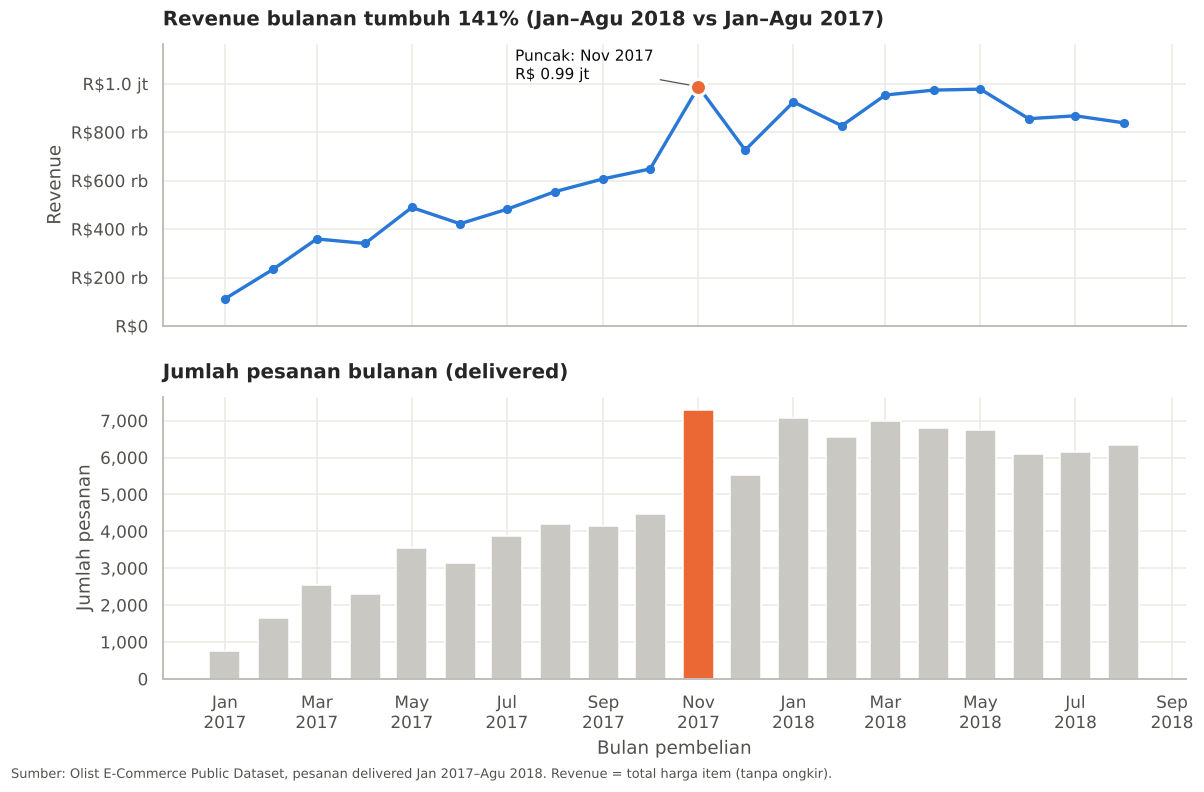

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={'hspace': 0.25})
x = monthly_df['order_month']
peak_idx = monthly_df['revenue'].idxmax()

# Panel 1: revenue
ax = axes[0]
ax.plot(x, monthly_df['revenue'], color=BLUE, linewidth=2.2, marker='o', markersize=5)
ax.scatter(x[peak_idx], monthly_df.loc[peak_idx, 'revenue'], s=110, color=ORANGE, zorder=5,
           edgecolor='white', linewidth=2)
ax.annotate(f"Puncak: {x[peak_idx]:%b %Y}\nR$ {monthly_df.loc[peak_idx, 'revenue'] / 1e6:.2f} jt",
            xy=(x[peak_idx], monthly_df.loc[peak_idx, 'revenue']), xytext=(-120, 5),
            textcoords='offset points', fontsize=10, color=INK,
            arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.set_ylim(0, monthly_df['revenue'].max() * 1.18)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(rupiah_like))
ax.set_ylabel('Revenue')
ax.set_title(f'Revenue bulanan tumbuh {(rev_2018 / rev_2017 - 1) * 100:.0f}% (Jan–Agu 2018 vs Jan–Agu 2017)',
             loc='left')

# Panel 2: jumlah pesanan
ax = axes[1]
ax.bar(x, monthly_df['order_count'], width=20, color=GRAY)
ax.bar(x[peak_idx], monthly_df.loc[peak_idx, 'order_count'], width=20, color=ORANGE)
ax.set_ylabel('Jumlah pesanan')
ax.set_title('Jumlah pesanan bulanan (delivered)', loc='left')
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
ax.set_xlabel('Bulan pembelian')
fig.text(0.01, -0.01, 'Sumber: Olist E-Commerce Public Dataset, pesanan delivered Jan 2017–Agu 2018. Revenue = total harga item (tanpa ongkir).',
         fontsize=8.5, color=INK2)
plt.show()

**Insight:**
- Revenue Januari–Agustus 2018 mencapai R\$7,22 juta, naik **141,1%** dibandingkan periode yang sama tahun 2017 (R\$2,99 juta). Pertumbuhan paling cepat terjadi sepanjang 2017.
- **Puncak revenue terjadi pada November 2017** (R\$987.648 dari 7.288 pesanan). Lonjakan ini bertepatan dengan periode Black Friday (24 November 2017), lalu revenue turun 26,5% pada Desember.
- Sepanjang 2018, revenue cenderung **stabil (plateau)** di kisaran R\$0,84–0,98 juta per bulan dan sedikit melemah sejak Juni 2018. Artinya, fase pertumbuhan cepat sudah melambat dan perlu pendorong baru.

### Pertanyaan 2: Kategori apa yang masuk 10 besar penyumbang revenue Jan 2017–Agu 2018, berapa kontribusinya, dan kategori mana yang paling kecil?

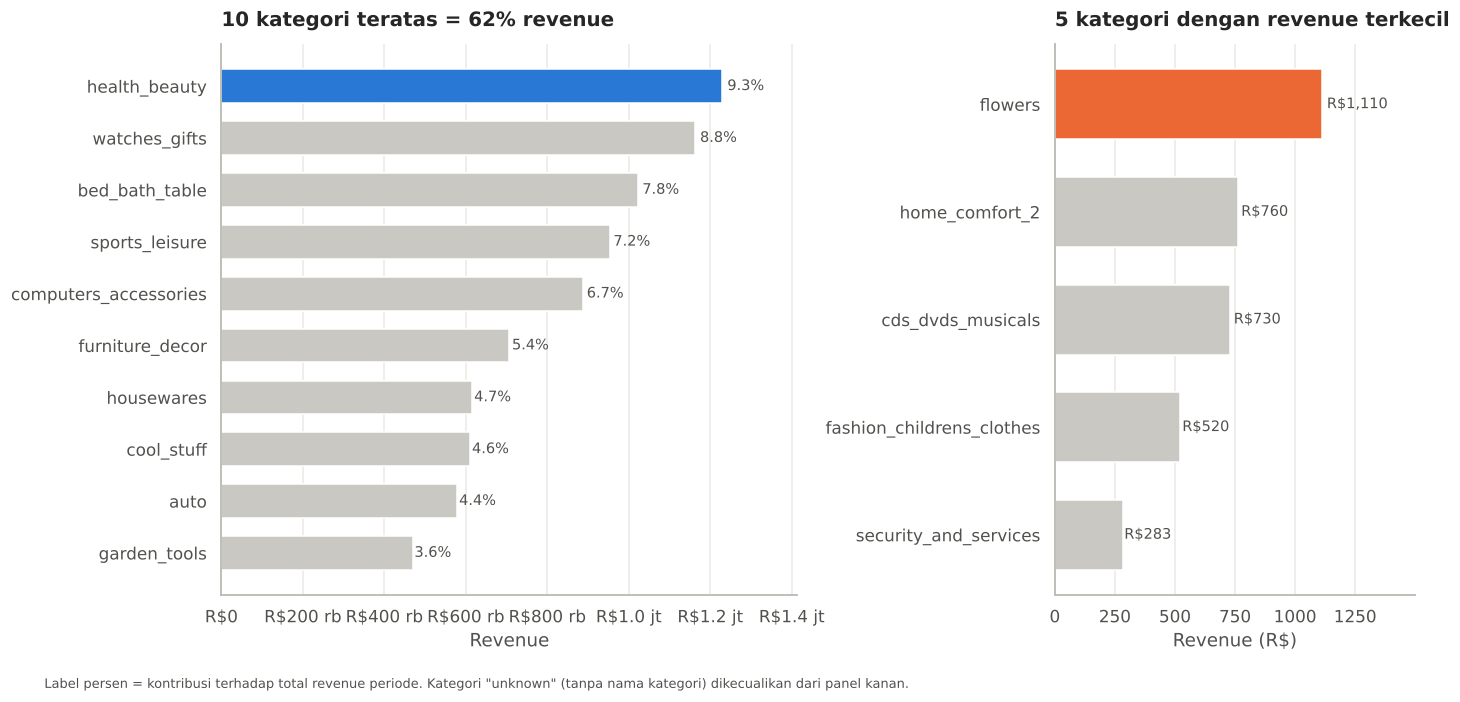

In [ ]:
top10 = category_df.head(10).iloc[::-1]
bottom5 = category_df[category_df['product_category'] != 'unknown'].tail(5).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={'width_ratios': [1.6, 1], 'wspace': 0.55})

ax = axes[0]
colors = [GRAY] * 9 + [BLUE]
bars = ax.barh(top10['product_category'], top10['revenue'], color=colors, height=0.65)
for bar, share in zip(bars, top10['share_%']):
    ax.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,
            f'{share:.1f}%', va='center', fontsize=9.5, color=INK2)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(rupiah_like))
ax.set_xlim(0, top10['revenue'].max() * 1.15)
ax.set_xlabel('Revenue')
ax.set_ylabel(None)
ax.set_title(f"10 kategori teratas = {category_df.head(10)['share_%'].sum():.0f}% revenue", loc='left')
ax.grid(axis='y', visible=False)

ax = axes[1]
bars = ax.barh(bottom5['product_category'], bottom5['revenue'], color=[GRAY] * 4 + [ORANGE], height=0.65)
for bar in bars:
    ax.text(bar.get_width() * 1.02, bar.get_y() + bar.get_height() / 2,
            f'R${bar.get_width():,.0f}', va='center', fontsize=9.5, color=INK2)
ax.set_xlim(0, bottom5['revenue'].max() * 1.35)
ax.set_xlabel('Revenue (R$)')
ax.set_title('5 kategori dengan revenue terkecil', loc='left')
ax.grid(axis='y', visible=False)
fig.text(0.01, -0.02, 'Label persen = kontribusi terhadap total revenue periode. Kategori "unknown" (tanpa nama kategori) dikecualikan dari panel kanan.',
         fontsize=8.5, color=INK2)
plt.show()

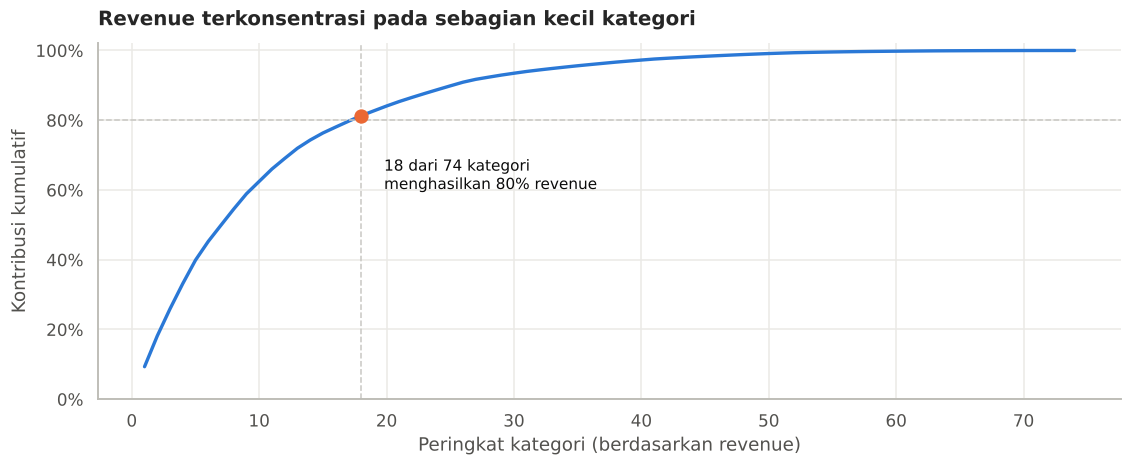

In [ ]:
# Kurva kontribusi kumulatif (Pareto) untuk melihat konsentrasi revenue
fig, ax = plt.subplots(figsize=(12, 4.2))
rank = np.arange(1, len(category_df) + 1)
ax.plot(rank, category_df['cumulative_share_%'], color=BLUE, linewidth=2.2)
n80 = int((category_df['cumulative_share_%'] < 80).sum() + 1)
ax.axhline(80, color=GRAY, linestyle='--', linewidth=1)
ax.axvline(n80, color=GRAY, linestyle='--', linewidth=1)
ax.scatter(n80, category_df.loc[n80 - 1, 'cumulative_share_%'], color=ORANGE, s=70, zorder=5)
ax.annotate(f'{n80} dari {len(category_df)} kategori\nmenghasilkan 80% revenue', xy=(n80, 80),
            xytext=(15, -45), textcoords='offset points', fontsize=10, color=INK)
ax.set_ylim(0, 102)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_xlabel('Peringkat kategori (berdasarkan revenue)')
ax.set_ylabel('Kontribusi kumulatif')
ax.set_title('Revenue terkonsentrasi pada sebagian kecil kategori', loc='left')
plt.show()

**Insight:**
- 10 kategori teratas menyumbang **62,5%** dari total revenue. Tiga teratas adalah `health_beauty` (R\$1,23 juta; 9,3%), `watches_gifts` (R\$1,16 juta; 8,8%), dan `bed_bath_table` (R\$1,02 juta; 7,8%).
- Pola tiap kategori berbeda. `watches_gifts` mengandalkan harga rata-rata tinggi (R\$198,73 per item), sedangkan `bed_bath_table` mengandalkan volume (10.945 item terjual, terbanyak di antara semua kategori).
- Kurva Pareto menunjukkan **18 dari 74 kategori menghasilkan 80% revenue**.
- Kategori dengan revenue terkecil adalah `security_and_services` (R\$283 dari 2 item), disusul `fashion_childrens_clothes` dan `cds_dvds_musicals`. Kontribusinya hampir nol (di bawah 0,01%).

### Pertanyaan 3: Berapa selisih rata-rata review score pesanan tepat waktu vs terlambat Jan 2017–Agu 2018, dan state mana dengan keterlambatan tertinggi?

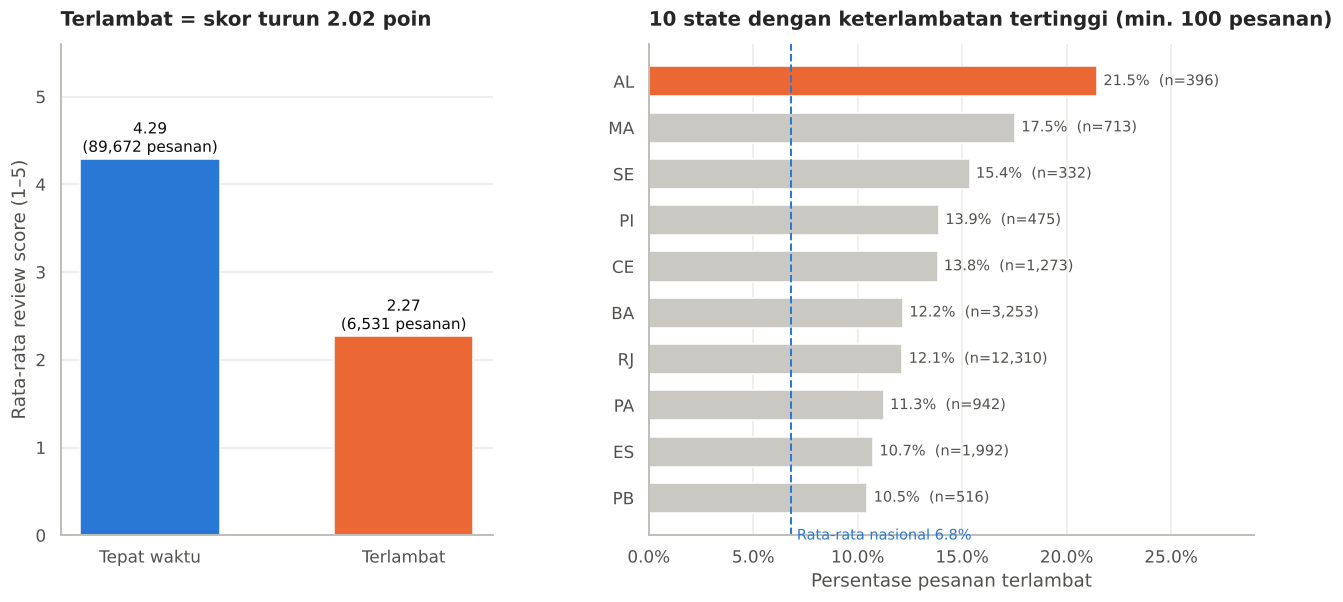

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={'width_ratios': [1, 1.4], 'wspace': 0.3})

# Panel kiri: rata-rata review score
ax = axes[0]
vals = late_summary['avg_review']
bars = ax.bar(vals.index, vals.values, color=[BLUE, ORANGE], width=0.55)
for bar, (_, row) in zip(bars, late_summary.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.08,
            f"{row['avg_review']:.2f}\n({int(row['order_count']):,} pesanan)", ha='center', fontsize=10, color=INK)
ax.set_ylim(0, 5.6)
ax.set_ylabel('Rata-rata review score (1–5)')
gap = vals['Tepat waktu'] - vals['Terlambat']
ax.set_title(f'Terlambat = skor turun {gap:.2f} poin', loc='left')
ax.grid(axis='x', visible=False)

# Panel kanan: 10 state dengan persentase keterlambatan tertinggi
ax = axes[1]
top_state = state_df[state_df['order_count'] >= 100].head(10).iloc[::-1]
national = order_level['is_late'].mean() * 100
bars = ax.barh(top_state.index, top_state['late_pct'], color=[GRAY] * 9 + [ORANGE], height=0.65)
for bar, n in zip(bars, top_state['order_count']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f'{bar.get_width():.1f}%  (n={n:,})', va='center', fontsize=9.5, color=INK2)
ax.axvline(national, color=BLUE, linestyle='--', linewidth=1.3)
ax.text(national + 0.3, -0.9, f'Rata-rata nasional {national:.1f}%', color=BLUE, fontsize=9.5)
ax.set_xlim(0, top_state['late_pct'].max() * 1.35)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_xlabel('Persentase pesanan terlambat')
ax.set_title('10 state dengan keterlambatan tertinggi (min. 100 pesanan)', loc='left')
ax.grid(axis='y', visible=False)
plt.show()

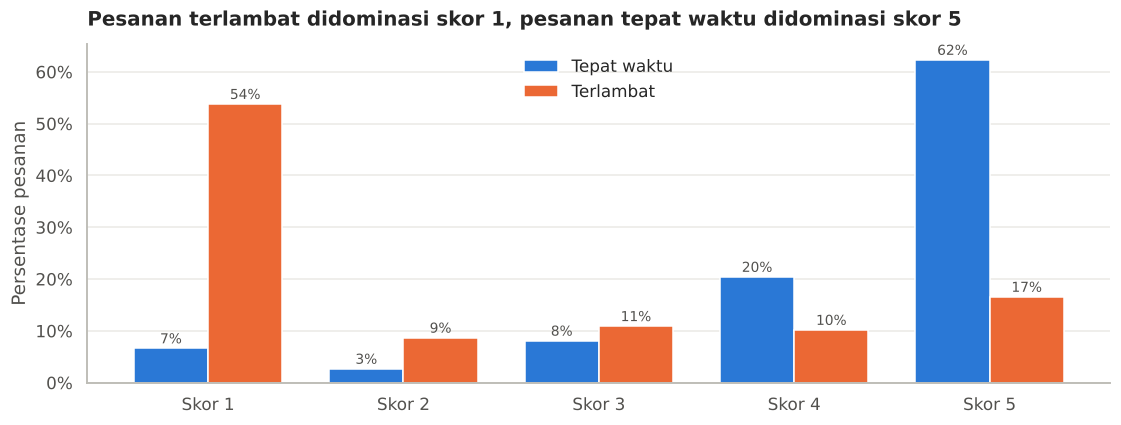

In [ ]:
# Komposisi review score untuk melihat di mana perbedaannya terjadi
dist = (order_level.dropna(subset=['review_score'])
        .groupby('is_late')['review_score'].value_counts(normalize=True)
        .mul(100).unstack().rename(index={False: 'Tepat waktu', True: 'Terlambat'}))
fig, ax = plt.subplots(figsize=(12, 4))
width = 0.38
xs = np.arange(1, 6)
ax.bar(xs - width / 2, dist.loc['Tepat waktu'], width, color=BLUE, label='Tepat waktu')
ax.bar(xs + width / 2, dist.loc['Terlambat'], width, color=ORANGE, label='Terlambat')
for xi, v in zip(xs, dist.loc['Terlambat']):
    ax.text(xi + width / 2, v + 1, f'{v:.0f}%', ha='center', fontsize=9, color=INK2)
for xi, v in zip(xs, dist.loc['Tepat waktu']):
    ax.text(xi - width / 2, v + 1, f'{v:.0f}%', ha='center', fontsize=9, color=INK2)
ax.set_xticks(xs, [f'Skor {i}' for i in xs])
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylabel('Persentase pesanan')
ax.set_title('Pesanan terlambat didominasi skor 1, pesanan tepat waktu didominasi skor 5', loc='left')
ax.legend(frameon=False)
ax.grid(axis='x', visible=False)
plt.show()

**Insight:**
- Pesanan yang tiba tepat waktu memiliki rata-rata review **4,29**, sedangkan pesanan terlambat hanya **2,27**. Selisihnya **2,02 poin**, atau hampir setengah skala penilaian.
- Perbedaan paling jelas terlihat pada skor ekstrem: 61% pesanan terlambat mendapat review buruk (skor 1–2), dibandingkan hanya 9% pada pesanan tepat waktu.
- **Alagoas (AL) memiliki persentase keterlambatan tertinggi (21,5%)**, lebih dari tiga kali rata-rata nasional (6,8%). State lain yang tinggi adalah Maranhão/MA (17,5%) dan Sergipe/SE (15,4%), semuanya di wilayah Timur Laut.
- Rio de Janeiro (RJ) perlu perhatian khusus. Persentasenya 12,1%, tetapi karena volumenya besar (12.310 pesanan), RJ menyumbang 1.495 atau sekitar 23% dari seluruh pesanan terlambat.

## Analisis Lanjutan (Opsional)

Tiga teknik analisis lanjutan diterapkan tanpa algoritma machine learning:
1. **RFM Analysis** untuk mengelompokkan pelanggan berdasarkan perilaku belanja.
2. **Geospatial Analysis** untuk melihat sebaran pelanggan dan kinerja pengiriman berdasarkan lokasi.
3. **Clustering dengan binning (manual grouping)** untuk mengelompokkan pesanan berdasarkan lama pengiriman dan melihat dampaknya pada kepuasan.

### 1. RFM Analysis

**Tujuan:** mengetahui siapa pelanggan paling bernilai dan siapa yang berisiko berhenti belanja, sehingga strategi pemasaran bisa dibedakan per kelompok.

- **Recency**: jumlah hari sejak pembelian terakhir pelanggan sampai tanggal acuan (1 hari setelah transaksi terakhir di dataset, yaitu 30 Agustus 2018).
- **Frequency**: jumlah pesanan unik per pelanggan selama Jan 2017–Agu 2018.
- **Monetary**: total belanja (revenue) per pelanggan selama periode yang sama.

Identitas pelanggan memakai `customer_unique_id` karena `customer_id` berbeda di setiap pesanan.

In [ ]:
reference_date = all_df['order_purchase_timestamp'].max().normalize() + pd.Timedelta(days=1)
rfm_df = (all_df.groupby('customer_unique_id')
          .agg(last_purchase=('order_purchase_timestamp', 'max'),
               frequency=('order_id', 'nunique'),
               monetary=('price', 'sum'))
          .reset_index())
rfm_df['recency'] = (reference_date - rfm_df['last_purchase']).dt.days
rfm_df = rfm_df.drop(columns='last_purchase')
print('Tanggal acuan:', reference_date.date())
rfm_df[['recency', 'frequency', 'monetary']].describe()

Tanggal acuan: 2018-08-30


,recency,frequency,monetary
count,"93,096.00","93,096.00","93,096.00"
mean,236.25,1.03,141.57
std,150.94,0.21,215.77
min,0.00,1.00,0.85
25%,114.00,1.00,47.65
50%,218.00,1.00,89.70
75%,345.00,1.00,154.16
max,601.00,15.00,"13,440.00"


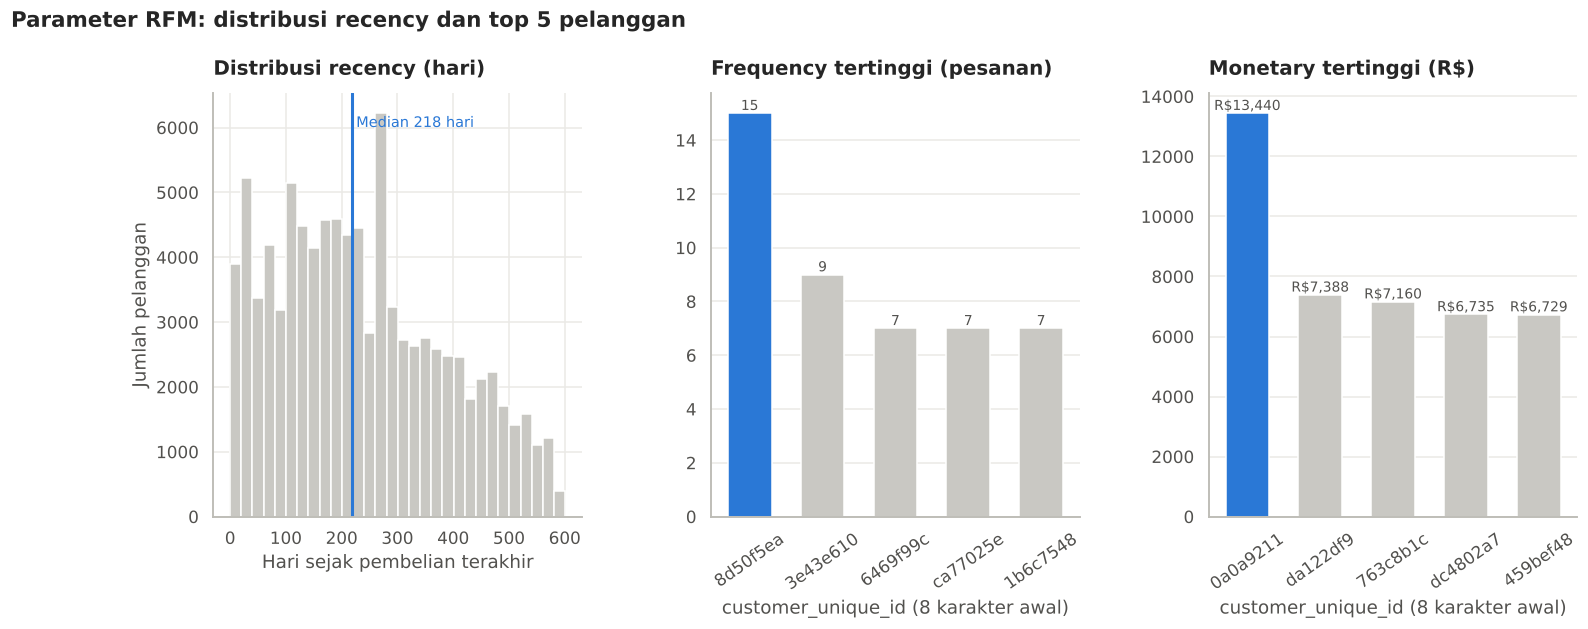

In [ ]:
rfm_df['short_id'] = rfm_df['customer_unique_id'].str[:8]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={'wspace': 0.35})
# Banyak pelanggan memiliki recency 0 hari, sehingga panel recency ditampilkan sebagai distribusi
ax = axes[0]
ax.hist(rfm_df['recency'], bins=30, color=GRAY, edgecolor='white')
ax.axvline(rfm_df['recency'].median(), color=BLUE, linewidth=2)
ax.text(rfm_df['recency'].median() + 8, ax.get_ylim()[1] * 0.92,
        f"Median {rfm_df['recency'].median():.0f} hari", color=BLUE, fontsize=9.5)
ax.set_title('Distribusi recency (hari)', loc='left')
ax.set_xlabel('Hari sejak pembelian terakhir')
ax.set_ylabel('Jumlah pelanggan')
specs = [
    ('frequency', False, 'Frequency tertinggi (pesanan)', '{:.0f}'),
    ('monetary', False, 'Monetary tertinggi (R$)', 'R${:,.0f}'),
]
for ax, (col, asc, title, fmt) in zip(axes[1:], specs):
    top = rfm_df.sort_values(col, ascending=asc).head(5)
    bars = ax.bar(top['short_id'], top[col], color=[BLUE] + [GRAY] * 4, width=0.6)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), fmt.format(bar.get_height()),
                ha='center', va='bottom', fontsize=9, color=INK2)
    ax.set_title(title, loc='left')
    ax.set_xlabel('customer_unique_id (8 karakter awal)')
    ax.tick_params(axis='x', rotation=35)
    ax.grid(axis='x', visible=False)
fig.suptitle('Parameter RFM: distribusi recency dan top 5 pelanggan', x=0.01, ha='left', fontweight='bold', fontsize=14, y=1.03)
plt.show()

**Segmentasi RFM berbasis aturan (rule-based), tanpa machine learning:**

- **R_score dan M_score (1–5)** dibuat dengan *quantile binning* (`pd.qcut`) sehingga tiap skor berisi sekitar 20% pelanggan. Untuk recency, makin kecil nilainya makin tinggi skornya.
- **F_score** dibuat dengan *manual binning* karena sebagian besar pelanggan hanya belanja sekali: 1 pesanan = 1, 2 pesanan = 3, 3 pesanan atau lebih = 5.
- Segmen ditentukan dari kombinasi skor:

| Segmen | Aturan | Makna |
|---|---|---|
| Champions | F ≥ 3 dan R ≥ 4 | Belanja berulang dan masih aktif |
| Loyal (perlu diaktifkan) | F ≥ 3 dan R ≤ 3 | Pernah berulang, mulai jarang |
| New Big Spender | F = 1, R ≥ 4, M ≥ 4 | Pelanggan baru dengan belanja besar |
| New Customer | F = 1, R ≥ 4, M ≤ 3 | Pelanggan baru, belanja kecil–sedang |
| Need Attention | F = 1, R = 3 | Mulai tidak aktif |
| At Risk (high value) | F = 1, R ≤ 2, M ≥ 4 | Belanja besar tetapi sudah lama tidak kembali |
| Hibernating | Sisanya | Sudah lama tidak aktif dan nilai belanja kecil |

In [ ]:
rfm_df['R_score'] = pd.qcut(rfm_df['recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_df['M_score'] = pd.qcut(rfm_df['monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_df['F_score'] = pd.cut(rfm_df['frequency'], bins=[0, 1, 2, np.inf], labels=[1, 3, 5]).astype(int)

def rfm_segment(row):
    r, f, m = row['R_score'], row['F_score'], row['M_score']
    if f >= 3:
        return 'Champions' if r >= 4 else 'Loyal (perlu diaktifkan)'
    if r >= 4:
        return 'New Big Spender' if m >= 4 else 'New Customer'
    if r == 3:
        return 'Need Attention'
    if m >= 4:
        return 'At Risk (high value)'
    return 'Hibernating'

rfm_df['segment'] = rfm_df.apply(rfm_segment, axis=1)
segment_summary = (rfm_df.groupby('segment')
                   .agg(customers=('customer_unique_id', 'count'), avg_recency=('recency', 'mean'),
                        avg_frequency=('frequency', 'mean'), avg_monetary=('monetary', 'mean'),
                        total_monetary=('monetary', 'sum'))
                   .sort_values('customers', ascending=False))
segment_summary['customer_%'] = segment_summary['customers'] / segment_summary['customers'].sum() * 100
segment_summary['revenue_%'] = segment_summary['total_monetary'] / segment_summary['total_monetary'].sum() * 100
segment_summary

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,customer_%,revenue_%
segment,,,,,,,
Hibernating,22539,392.72,1.00,56.00,"1,262,089.29",24.21,9.58
New Customer,21716,89.12,1.00,55.69,"1,209,450.44",23.33,9.18
Need Attention,18048,219.30,1.00,130.00,"2,346,286.40",19.39,17.80
New Big Spender,14400,91.10,1.00,267.85,"3,857,102.44",15.47,29.27
At Risk (high value),13604,391.51,1.00,277.82,"3,779,494.34",14.61,28.68
Loyal (perlu diaktifkan),1592,317.72,2.08,251.97,"401,143.56",1.71,3.04
Champions,1197,87.97,2.15,270.85,"324,211.48",1.29,2.46


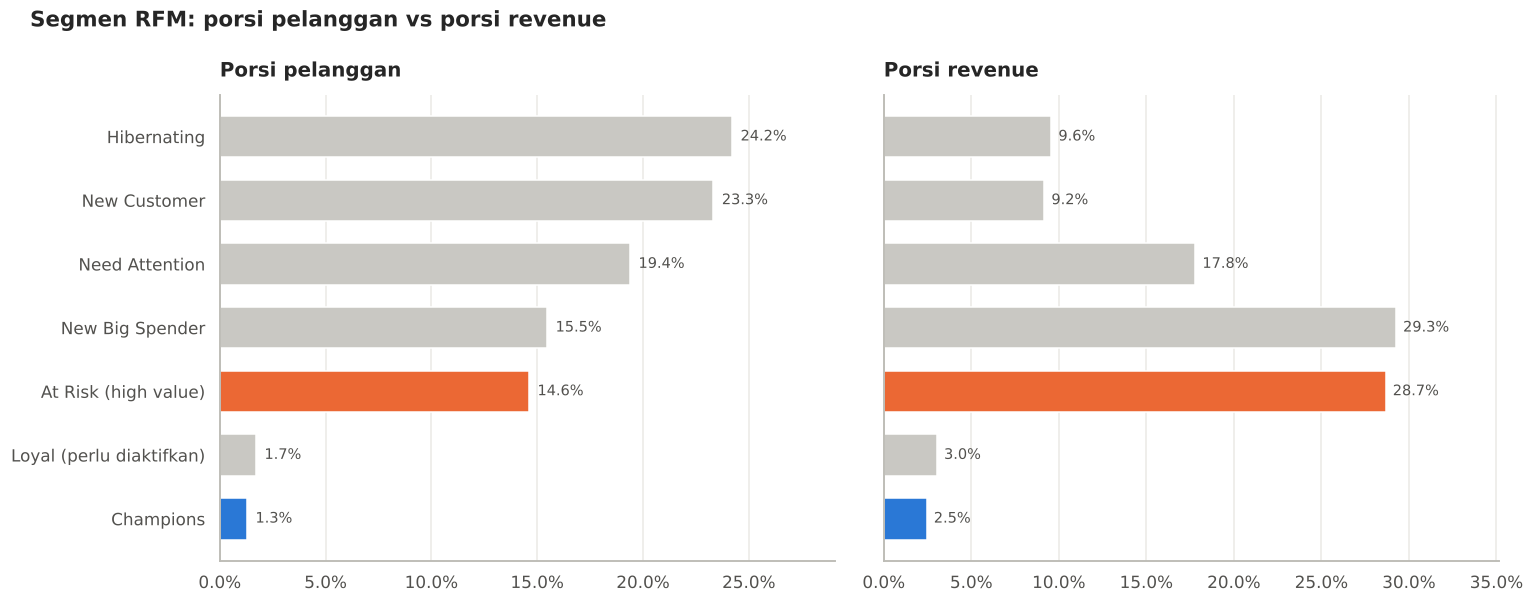

In [ ]:
seg = segment_summary.sort_values('customers')
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True, gridspec_kw={'wspace': 0.08})
highlight = 'At Risk (high value)'
for ax, col, title in [(axes[0], 'customer_%', 'Porsi pelanggan'), (axes[1], 'revenue_%', 'Porsi revenue')]:
    colors = [ORANGE if s == highlight else (BLUE if s == 'Champions' else GRAY) for s in seg.index]
    bars = ax.barh(seg.index, seg[col], color=colors, height=0.65)
    for bar in bars:
        ax.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2, f'{bar.get_width():.1f}%',
                va='center', fontsize=9.5, color=INK2)
    ax.set_xlim(0, seg[col].max() * 1.2)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter())
    ax.set_title(title, loc='left')
    ax.grid(axis='y', visible=False)
fig.suptitle('Segmen RFM: porsi pelanggan vs porsi revenue', x=0.01, ha='left', fontweight='bold', fontsize=14, y=1.02)
plt.show()

**Insight RFM:**
- Pelanggan Olist hampir semuanya **pembeli satu kali**: median recency 218 hari dan rata-rata frequency hanya 1,03 pesanan.
- Segmen **At Risk (high value)** hanya 14,6% pelanggan, tetapi menyumbang **28,7% revenue**. Mereka pernah belanja besar (rata-rata R\$278) tetapi sudah lebih dari setahun tidak kembali (rata-rata recency 392 hari). Segmen ini paling layak dijadikan target kampanye *win-back*.
- Segmen **New Big Spender** (15,5% pelanggan, 29,3% revenue) adalah pelanggan baru bernilai tinggi. Momen terbaik untuk mengubah mereka menjadi pelanggan berulang adalah dalam 1–3 bulan setelah pembelian pertama.
- **Champions** hanya 1,3% pelanggan (1.197 orang). Program loyalitas masih punya ruang besar untuk dikembangkan.

### 2. Geospatial Analysis

**Tujuan:** melihat di wilayah mana pelanggan terkonsentrasi dan bagaimana kinerja pengiriman berbeda antarwilayah. Koordinat pelanggan diambil dari tabel `geolocation` yang sudah dibersihkan (rata-rata titik per prefix kode pos). Peta dibuat dengan scatter plot lintang–bujur menggunakan matplotlib, sehingga tidak memerlukan library peta tambahan.

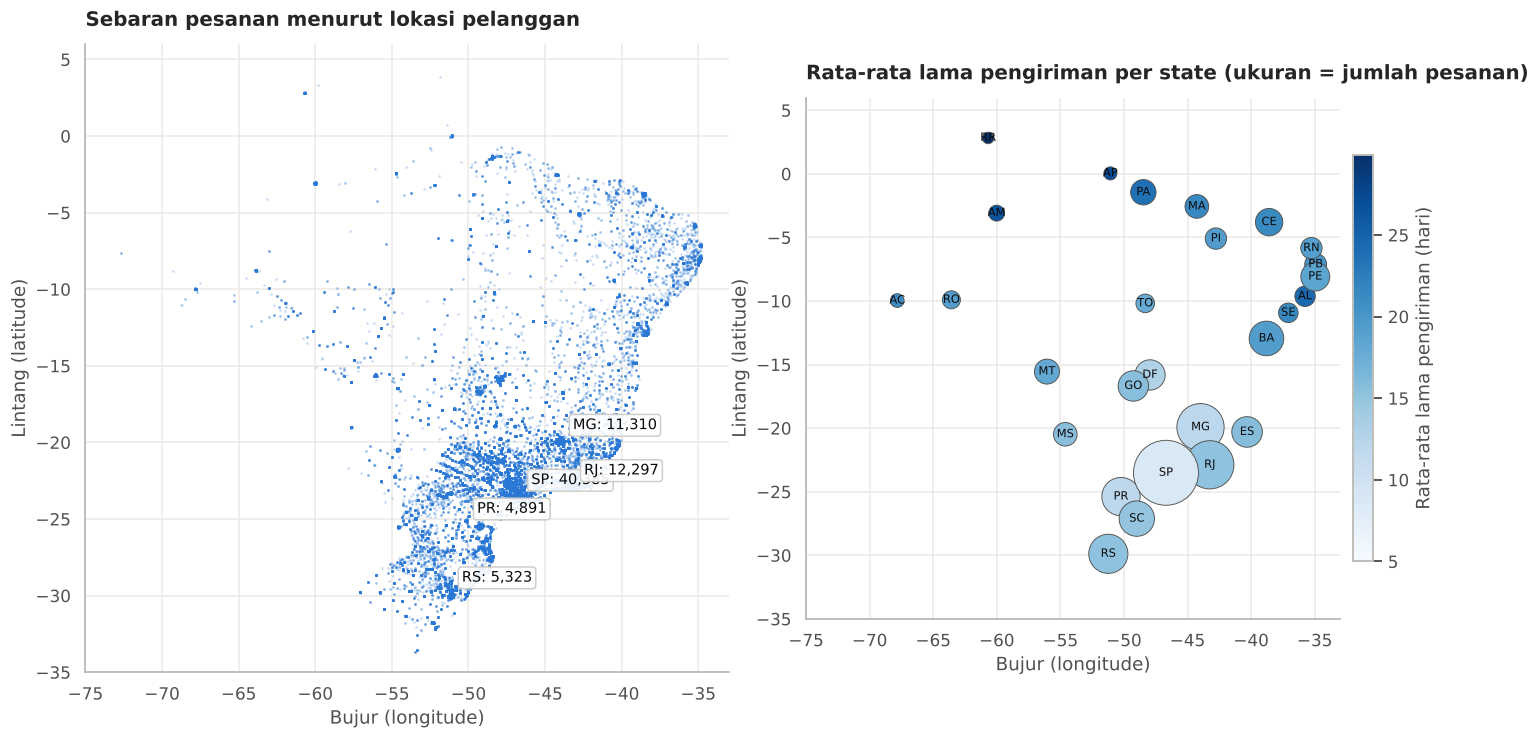

In [ ]:
cust_points = order_level.dropna(subset=['lat', 'lng'])
state_geo = (order_level.dropna(subset=['lat', 'lng'])
             .groupby('customer_state')
             .agg(lat=('lat', 'median'), lng=('lng', 'median'), orders=('order_id', 'count'),
                  avg_delivery_days=('delivery_days', 'mean'), late_pct=('is_late', lambda s: s.mean() * 100),
                  avg_review=('review_score', 'mean'))
             .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={'wspace': 0.12})

# Peta 1: sebaran titik pelanggan
ax = axes[0]
ax.scatter(cust_points['lng'], cust_points['lat'], s=1, alpha=0.15, color=BLUE, rasterized=True)
for _, r in state_geo.nlargest(5, 'orders').iterrows():
    ax.annotate(f"{r['customer_state']}: {r['orders']:,}", (r['lng'], r['lat']), fontsize=9.5, color=INK,
                xytext=(8, 8), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=GRAY, alpha=0.9))
ax.set_title('Sebaran pesanan menurut lokasi pelanggan', loc='left')

# Peta 2: rata-rata lama pengiriman per state (warna sekuensial satu hue) dan volume (ukuran)
ax = axes[1]
sc = ax.scatter(state_geo['lng'], state_geo['lat'], s=np.sqrt(state_geo['orders']) * 9,
                c=state_geo['avg_delivery_days'], cmap='Blues', vmin=5, edgecolor=INK2, linewidth=0.6)
for _, r in state_geo.iterrows():
    ax.text(r['lng'], r['lat'], r['customer_state'], ha='center', va='center', fontsize=7.5, color=INK)
cbar = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label('Rata-rata lama pengiriman (hari)')
ax.set_title('Rata-rata lama pengiriman per state (ukuran = jumlah pesanan)', loc='left')

for ax in axes:
    ax.set_xlim(-75, -33); ax.set_ylim(-35, 6)
    ax.set_aspect('equal')
    ax.set_xlabel('Bujur (longitude)'); ax.set_ylabel('Lintang (latitude)')
plt.show()

In [ ]:
# Perbandingan wilayah: Tenggara (dekat pusat seller) vs wilayah lain
region_map = {
    'SP': 'Tenggara', 'RJ': 'Tenggara', 'MG': 'Tenggara', 'ES': 'Tenggara',
    'PR': 'Selatan', 'SC': 'Selatan', 'RS': 'Selatan',
    'DF': 'Tengah-Barat', 'GO': 'Tengah-Barat', 'MT': 'Tengah-Barat', 'MS': 'Tengah-Barat',
    'BA': 'Timur Laut', 'PE': 'Timur Laut', 'CE': 'Timur Laut', 'MA': 'Timur Laut', 'PB': 'Timur Laut',
    'RN': 'Timur Laut', 'AL': 'Timur Laut', 'PI': 'Timur Laut', 'SE': 'Timur Laut',
    'PA': 'Utara', 'AM': 'Utara', 'RO': 'Utara', 'TO': 'Utara', 'AP': 'Utara', 'AC': 'Utara', 'RR': 'Utara',
}
order_level = order_level.assign(region=order_level['customer_state'].map(region_map))
region_df = (order_level.groupby('region')
             .agg(orders=('order_id', 'count'), avg_delivery_days=('delivery_days', 'mean'),
                  late_pct=('is_late', lambda s: s.mean() * 100), avg_review=('review_score', 'mean'))
             .sort_values('avg_delivery_days'))
region_df['order_share_%'] = region_df['orders'] / region_df['orders'].sum() * 100
print('Porsi seller berbasis di SP:', f"{(sellers_df['seller_state'] == 'SP').mean() * 100:.1f}%")
region_df

Porsi seller berbasis di SP: 59.7%


,orders,avg_delivery_days,late_pct,avg_review,order_share_%
region,,,,,
Tenggara,66020,10.73,6.13,4.18,68.63
Selatan,13767,14.02,5.92,4.19,14.31
Tengah-Barat,5610,15.01,6.54,4.13,5.83
Timur Laut,9015,19.99,12.76,3.97,9.37
Utara,1791,22.59,8.60,4.03,1.86


**Insight Geospasial:**
- Pesanan sangat terkonsentrasi di **wilayah Tenggara** (SP, RJ, MG, ES), yaitu 68,6% dari total pesanan. SP sendiri menyumbang lebih dari 40 ribu pesanan.
- Lama pengiriman meningkat seiring jarak dari São Paulo, tempat 59,7% seller berada. Rata-rata pengiriman di Tenggara 10,7 hari, sedangkan Timur Laut 20,0 hari dan Utara 22,6 hari.
- **Timur Laut adalah wilayah paling bermasalah**: persentase keterlambatan tertinggi (12,8%) dan rata-rata review terendah (3,97). Wilayah Utara lebih lama pengirimannya, tetapi keterlambatannya lebih rendah (8,6%) karena estimasi yang diberikan juga lebih panjang. Jadi akurasi estimasi sama pentingnya dengan kecepatan kirim.

### 3. Clustering dengan Binning: kelompok lama pengiriman

**Tujuan:** mengubah lama pengiriman (angka kontinu) menjadi kelompok yang mudah dipahami bisnis, lalu melihat pada titik mana kepuasan pelanggan mulai turun tajam. Batas kelompok dipilih manual berdasarkan satuan minggu agar mudah dijadikan target layanan (SLA).

In [ ]:
bins = [0, 7, 14, 21, 30, np.inf]
labels = ['≤ 1 minggu', '8–14 hari', '15–21 hari', '22–30 hari', '> 30 hari']
order_level = order_level.assign(delivery_group=pd.cut(order_level['delivery_days'], bins=bins, labels=labels))
delivery_cluster = (order_level.groupby('delivery_group', observed=True)
                    .agg(orders=('order_id', 'count'), avg_review=('review_score', 'mean'),
                         pct_low_review=('review_score', lambda s: (s <= 2).mean() * 100),
                         late_pct=('is_late', lambda s: s.mean() * 100)))
delivery_cluster['order_share_%'] = delivery_cluster['orders'] / delivery_cluster['orders'].sum() * 100
delivery_cluster

,orders,avg_review,pct_low_review,late_pct,order_share_%
delivery_group,,,,,
≤ 1 minggu,26038,4.42,7.42,0.23,27.07
8–14 hari,40111,4.31,8.91,0.79,41.69
15–21 hari,17653,4.14,11.58,3.02,18.35
22–30 hari,7899,3.61,24.09,25.84,8.21
> 30 hari,4502,2.24,61.66,79.48,4.68


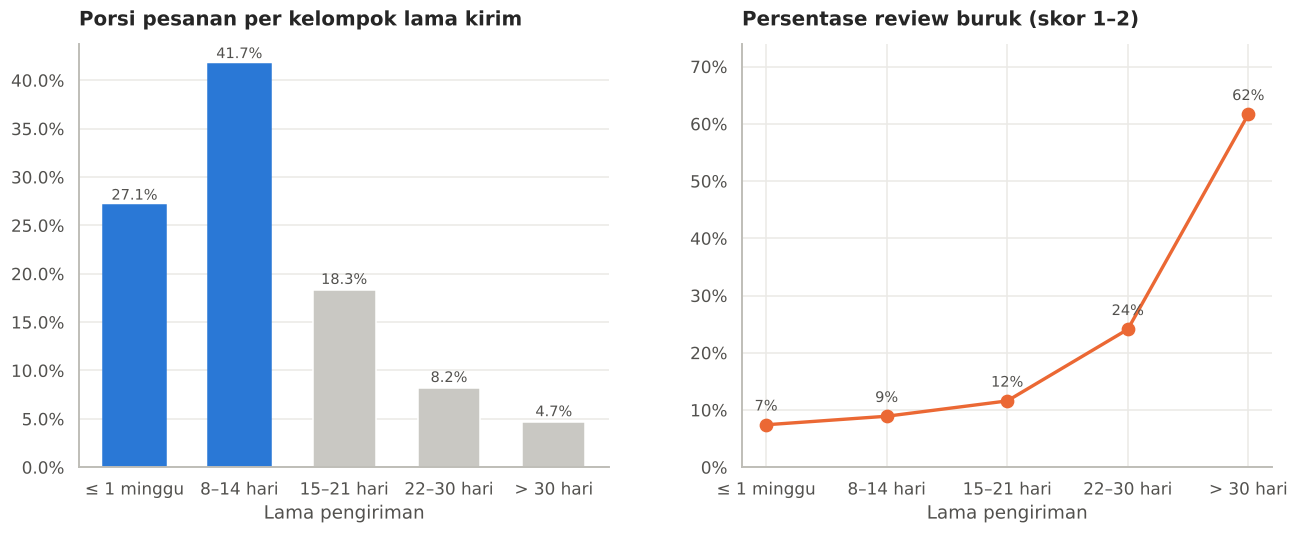

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'wspace': 0.25})
dc = delivery_cluster.reset_index()
ax = axes[0]
bars = ax.bar(dc['delivery_group'].astype(str), dc['order_share_%'], color=GRAY, width=0.6)
bars[0].set_color(BLUE); bars[1].set_color(BLUE)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.6, f'{bar.get_height():.1f}%',
            ha='center', fontsize=9.5, color=INK2)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_title('Porsi pesanan per kelompok lama kirim', loc='left')
ax.set_xlabel('Lama pengiriman')
ax.grid(axis='x', visible=False)

ax = axes[1]
ax.plot(dc['delivery_group'].astype(str), dc['pct_low_review'], color=ORANGE, marker='o', linewidth=2.2, markersize=8)
for xi, v in enumerate(dc['pct_low_review']):
    ax.text(xi, v + 2.5, f'{v:.0f}%', ha='center', fontsize=9.5, color=INK2)
ax.set_ylim(0, dc['pct_low_review'].max() * 1.2)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_title('Persentase review buruk (skor 1–2)', loc='left')
ax.set_xlabel('Lama pengiriman')
plt.show()

**Insight Clustering:**
- Sebanyak **68,8% pesanan tiba dalam 14 hari**, dengan persentase review buruk hanya 7–9%.
- Kepuasan masih relatif aman sampai 21 hari (review buruk 11,6%), lalu **turun tajam setelah 21 hari**: review buruk melonjak menjadi 24,1% (22–30 hari) dan 61,7% (lebih dari 30 hari).
- Batas 21 hari dapat dijadikan **ambang SLA (Service Level Agreement)** internal. Pesanan yang belum tiba setelah 14 hari perlu dipantau aktif sebelum melewati batas tersebut.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Revenue Olist tumbuh pesat, dari R\$2,99 juta (Jan–Agu 2017) menjadi R\$7,22 juta (Jan–Agu 2018), atau naik 141,1%. Puncak revenue bulanan terjadi pada **November 2017** (R\$987.648; 7.288 pesanan) yang bertepatan dengan Black Friday. Sepanjang 2018 revenue mendatar di kisaran R\$0,84–0,98 juta per bulan, menandakan pertumbuhan mulai melambat.
- **Conclusion pertanyaan 2:** 10 kategori teratas menyumbang **62,5% revenue**, dipimpin `health_beauty`, `watches_gifts`, dan `bed_bath_table`. Revenue sangat terkonsentrasi: 18 dari 74 kategori menghasilkan 80% revenue. Kategori dengan kontribusi terkecil adalah `security_and_services` (R\$283), sehingga kurang layak diprioritaskan.
- **Conclusion pertanyaan 3:** Keterlambatan pengiriman menurunkan rata-rata review score sebesar **2,02 poin** (4,29 menjadi 2,27) dan meningkatkan porsi review buruk dari 9% menjadi 61%. **Alagoas (AL)** memiliki persentase keterlambatan tertinggi (21,5%), dan wilayah Timur Laut secara umum paling bermasalah. RJ menyumbang jumlah pesanan terlambat terbanyak secara absolut.
- **Conclusion analisis lanjutan:** RFM menunjukkan retensi rendah (hanya 3% pelanggan belanja berulang), dengan segmen At Risk (high value) menyimpan 28,7% revenue historis. Binning lama pengiriman menunjukkan kepuasan turun tajam setelah 21 hari.

**Rekomendasi Action Item:**
- **Siapkan kampanye musiman sejak Oktober.** Tambah stok dan promosi untuk kategori 10 besar (terutama `health_beauty`, `watches_gifts`, `bed_bath_table`) menjelang Black Friday, lalu siapkan promo lanjutan pada Desember agar penurunan setelah puncak tidak sedalam 26,5%.
- **Fokuskan anggaran pemasaran dan akuisisi seller pada 18 kategori penyumbang 80% revenue.** Kategori berkontribusi sangat kecil cukup dipertahankan tanpa promosi berbayar.
- **Perbaiki logistik di Timur Laut, dimulai dari AL, MA, dan SE.** Opsi yang bisa diuji: kerja sama dengan kurir regional, gudang transit di wilayah tersebut, dan estimasi pengiriman yang lebih realistis. Untuk RJ, prioritaskan audit kinerja kurir karena volumenya besar.
- **Tetapkan SLA pengiriman maksimal 21 hari** dengan pemantauan proaktif untuk pesanan yang sudah lewat 14 hari. Kirim notifikasi dan kompensasi kecil (misalnya voucher) bila pesanan berisiko terlambat untuk menahan review buruk.
- **Jalankan kampanye retensi berbasis RFM:** voucher *win-back* untuk segmen At Risk (high value), program *second purchase* untuk New Big Spender dalam 30–90 hari setelah pembelian pertama, serta program loyalitas untuk Champions.

## Menyimpan Data untuk Dashboard

Data yang sudah bersih disimpan ke `dashboard/main_data.csv` agar dashboard Streamlit tidak perlu mengulang proses cleaning. Hanya kolom yang dipakai di dashboard yang disimpan supaya ukuran berkas tetap ringan.

In [ ]:
main_cols = ['order_id', 'order_item_id', 'customer_unique_id', 'customer_city', 'customer_state', 'lat', 'lng',
             'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date',
             'product_category', 'price', 'freight_value', 'review_score', 'delivery_days', 'is_late']
main_data = all_df[main_cols].copy()
main_data['lat'] = main_data['lat'].round(4)
main_data['lng'] = main_data['lng'].round(4)
main_data['delivery_days'] = main_data['delivery_days'].round(2)
main_data.to_csv('dashboard/main_data.csv', index=False)
print('Tersimpan:', main_data.shape)

Tersimpan: (109872, 16)
